In [13]:
import os
import pandas as pd
import scanpy as sc
from scipy.io import mmread
import anndata
import numpy as np

In [2]:
old_pd = sc.read_mtx('/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/weinreb/stateFate_inVitro_normed_counts.mtx')



In [10]:
old_pd.shape

(130887, 25289)

In [3]:
old_pd.X.max()

870.98303

In [7]:
clonal_info = mmread("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/weinreb/stateFate_inVitro_clone_matrix.mtx")

In [11]:
clonal_info.shape #all cells and all unique barcodes 

(130887, 5864)

In [21]:
np.sum(clonal_info, axis=1).max()

1

In [20]:
old_pd.obs["barcode"] = None

for cell in range(clonal_info.row.shape[0]): #going trough all cells that have a barcode
    old_pd.obs["barcode"][clonal_info.row[cell]] = clonal_info.col[cell]

In [22]:
gene_names = pd.read_table("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/raw_datasets/weinreb/stateFate_inVitro_gene_names.txt", header=None)

In [23]:
old_pd.var_names = gene_names[0]

In [24]:
adata = old_pd

In [25]:
import scanpy as sc
import numpy as np

# --- 1) Compute mitochondrial percentage ---
# Identify mitochondrial genes (human or mouse)
adata.var['mt'] = adata.var_names.str.upper().str.startswith('MT-')

# Calculate percentage
adata.obs['pct_mt'] = np.sum(
    adata[:, adata.var['mt']].X, axis=1
) / np.sum(adata.X, axis=1) * 100

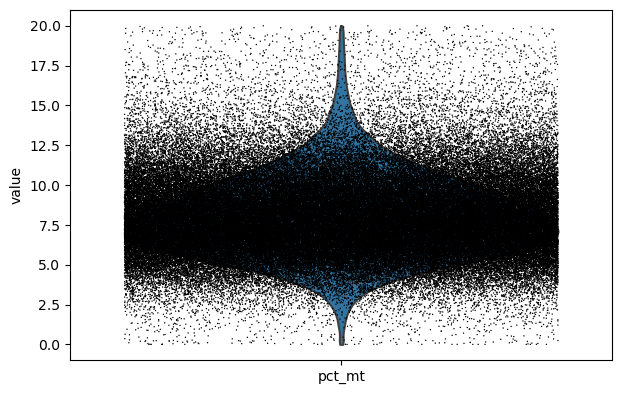

In [26]:
sc.pl.violin(adata, 'pct_mt', jitter=0.4)


In [ ]:
# not filtering more since authors already applied filtering at 20%


In [27]:
adata_no_nan = adata[~adata.obs["barcode"].isna()]

In [28]:
sc.pp.filter_cells(adata_no_nan, min_genes=100)
sc.pp.filter_genes(adata_no_nan, min_cells=2)

/home/proth/miniconda3/envs/TOSICA/lib/python3.8/site-packages/scanpy/preprocessing/_simple.py:140: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  adata.obs['n_genes'] = number


In [29]:
adata_no_nan

AnnData object with n_obs × n_vars = 49302 × 22636
    obs: 'barcode', 'pct_mt', 'n_genes'
    var: 'mt', 'n_cells'

In [30]:
sc.pp.normalize_total(adata_no_nan , target_sum=1e4)
sc.pp.log1p(adata_no_nan)

adata_filtered = adata_no_nan

In [31]:
adata_filtered.obs["barcode"] = adata_filtered.obs["barcode"].astype("str")

In [32]:
adata_filtered.obs_names

Index(['0', '1', '2', '4', '6', '8', '13', '14', '15', '16',
       ...
       '130866', '130869', '130872', '130873', '130874', '130875', '130876',
       '130877', '130879', '130883'],
      dtype='object', length=49302)

In [33]:
df = pd.DataFrame(adata_filtered.X.todense(), columns = adata_filtered.var_names)

In [34]:
df["barcode"] = adata_filtered.obs["barcode"].values

In [35]:
barcode_df = {}
k = 0
for i in df["barcode"].unique():
    barcode_df[i] = k
    k +=1

In [36]:
df["barcode_cont"] = df["barcode"].map(barcode_df)

In [37]:
df

,0610006L08Rik,0610007P14Rik,0610009B22Rik,0610009E02Rik,0610009L18Rik,0610009O20Rik,0610010F05Rik,0610010K14Rik,0610011F06Rik,0610012D04Rik,...,mt-Cytb,mt-Nd1,mt-Nd2,mt-Nd3,mt-Nd4,mt-Nd4l,mt-Nd5,mt-Nd6,barcode,barcode_cont
0,0.0,0.815365,0.000000,0.0,0.0,0.48858,0.0,0.0,0.000000,0.0,...,3.963857,4.659470,3.265760,1.897621,4.044280,0.488580,2.610071,0.000000,573,0
1,0.0,0.000000,0.731263,0.0,0.0,0.00000,0.0,0.0,1.149117,0.0,...,3.736542,4.765517,3.330151,1.854501,4.200802,0.000000,1.854501,0.000000,1440,1
2,0.0,0.000000,0.983441,0.0,0.0,0.00000,0.0,0.0,0.000000,0.0,...,4.141938,4.771996,3.195851,2.040514,3.968079,0.983441,1.795240,0.983441,394,2
3,0.0,0.000000,1.897701,0.0,0.0,0.00000,0.0,0.0,0.000000,0.0,...,4.004969,4.635406,2.251903,0.000000,3.895885,1.344240,2.891017,0.000000,1972,3
4,0.0,1.172837,0.000000,0.0,0.0,0.00000,0.0,0.0,0.000000,0.0,...,3.957309,4.039161,3.048340,2.666317,3.661752,0.000000,2.040368,0.000000,1450,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49297,0.0,1.184678,0.000000,0.0,0.0,0.00000,0.0,0.0,0.000000,0.0,...,3.619372,4.613771,3.165320,2.310407,3.734173,1.184678,2.055264,0.000000,12,4997
49298,0.0,0.000000,0.000000,0.0,0.0,0.00000,0.0,0.0,0.000000,0.0,...,4.098426,4.783239,3.929683,1.415411,4.368871,1.979118,2.808854,0.000000,267,4847
49299,0.0,0.000000,0.000000,0.0,0.0,0.00000,0.0,0.0,0.000000,0.0,...,4.492172,4.073199,3.554416,2.053287,4.413062,0.000000,2.680128,0.000000,3534,3893
49300,0.0,1.668259,0.000000,0.0,0.0,0.00000,0.0,0.0,0.000000,0.0,...,4.041964,4.560846,3.437866,2.262372,4.246305,0.000000,2.262372,0.000000,4945,4945


In [38]:
df["barcode_cont"].unique().shape == df["barcode"].unique().shape

True

In [39]:
df.drop(columns = ["barcode"], inplace = True)

In [40]:
df

,0610006L08Rik,0610007P14Rik,0610009B22Rik,0610009E02Rik,0610009L18Rik,0610009O20Rik,0610010F05Rik,0610010K14Rik,0610011F06Rik,0610012D04Rik,...,mt-Co3,mt-Cytb,mt-Nd1,mt-Nd2,mt-Nd3,mt-Nd4,mt-Nd4l,mt-Nd5,mt-Nd6,barcode_cont
0,0.0,0.815365,0.000000,0.0,0.0,0.48858,0.0,0.0,0.000000,0.0,...,3.109954,3.963857,4.659470,3.265760,1.897621,4.044280,0.488580,2.610071,0.000000,0
1,0.0,0.000000,0.731263,0.0,0.0,0.00000,0.0,0.0,1.149117,0.0,...,3.207186,3.736542,4.765517,3.330151,1.854501,4.200802,0.000000,1.854501,0.000000,1
2,0.0,0.000000,0.983441,0.0,0.0,0.00000,0.0,0.0,0.000000,0.0,...,2.875619,4.141938,4.771996,3.195851,2.040514,3.968079,0.983441,1.795240,0.983441,2
3,0.0,0.000000,1.897701,0.0,0.0,0.00000,0.0,0.0,0.000000,0.0,...,3.471593,4.004969,4.635406,2.251903,0.000000,3.895885,1.344240,2.891017,0.000000,3
4,0.0,1.172837,0.000000,0.0,0.0,0.00000,0.0,0.0,0.000000,0.0,...,3.148945,3.957309,4.039161,3.048340,2.666317,3.661752,0.000000,2.040368,0.000000,4
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
49297,0.0,1.184678,0.000000,0.0,0.0,0.00000,0.0,0.0,0.000000,0.0,...,2.682240,3.619372,4.613771,3.165320,2.310407,3.734173,1.184678,2.055264,0.000000,4997
49298,0.0,0.000000,0.000000,0.0,0.0,0.00000,0.0,0.0,0.000000,0.0,...,1.979118,4.098426,4.783239,3.929683,1.415411,4.368871,1.979118,2.808854,0.000000,4847
49299,0.0,0.000000,0.000000,0.0,0.0,0.00000,0.0,0.0,0.000000,0.0,...,2.889466,4.492172,4.073199,3.554416,2.053287,4.413062,0.000000,2.680128,0.000000,3893
49300,0.0,1.668259,0.000000,0.0,0.0,0.00000,0.0,0.0,0.000000,0.0,...,3.289057,4.041964,4.560846,3.437866,2.262372,4.246305,0.000000,2.262372,0.000000,4945


In [41]:
df.to_pickle("/fast/AG_Metzger/philipp/python_files/gene_signature/mutual_information_approach/November_25_ReDo/preprocessing/pkl_files_filtered/weinreb_all_genes.pkl")

